In [1]:

# Fixed baseline versus Multinomial NB using saved development folds.
# Does not load or evaluate final-test features.

from pathlib import Path
from datetime import datetime, timezone
import sys
import json
import hashlib

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

roots = [
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data/processed/acoustic_features_recording.csv").is_file()
]
assert len(roots) == 1
PROJECT_ROOT = roots[0]

artifact_dir = (
    PROJECT_ROOT / "data/processed/supervised/v1"
    / "assignment_artifacts_20261030T020845905141Z"
)
artifacts = json.loads(
    (artifact_dir / "artifact_manifest.json").read_text(encoding="utf-8")
)
feature_names = artifacts["feature_allowlist"]
CLASSES = ["CA", "AZ", "TX"]

module_path = PROJECT_ROOT / "research/src/supervised/representations.py"
assert hashlib.sha256(module_path.read_bytes()).hexdigest() == (
    artifacts["representation_module_sha256"]
), "Preprocessing module changed."

source_dir = str(PROJECT_ROOT / "research/src")
if source_dir not in sys.path:
    sys.path.insert(0, source_dir)

from supervised.representations import make_representations

fold_manifest = pd.read_csv(
    PROJECT_ROOT / artifacts["development_folds"],
    dtype={"recording_id": "string"},
)
training_export = pd.read_csv(
    artifact_dir / "development_train.csv",
    dtype={"recording_id": "string"},
)

assert training_export["recording_id"].is_unique
assert set(training_export["recording_id"]) == set(fold_manifest["recording_id"])

# Align features to the SAVED validation-fold order.
ordered = training_export.set_index("recording_id").loc[
    fold_manifest["recording_id"]
]
assert np.array_equal(
    ordered["model_state"].to_numpy(),
    fold_manifest["model_state"].to_numpy(),
)
assert np.array_equal(
    ordered["location_group"].to_numpy(),
    fold_manifest["location_group"].to_numpy(),
)

X = ordered[feature_names].reset_index(drop=True)
y = fold_manifest["model_state"].reset_index(drop=True)
assert X.shape == (184, 50)
assert np.isfinite(X.to_numpy()).all()

models = {
    # Predicts the most frequent training class; learns training class priors.
    "Prior baseline": DummyClassifier(strategy="prior"),
    "MNB: 3 bins, alpha=1": Pipeline([
        ("representation", make_representations()["multinomial_bins"]),
        ("classifier", MultinomialNB(alpha=1.0, fit_prior=True)),
    ]),
}

fold_results = []
oof_results = []

for name, template in models.items():
    for fold in range(5):
        validation_mask = fold_manifest["validation_fold"].eq(fold)
        train_idx = np.flatnonzero(~validation_mask.to_numpy())
        validation_idx = np.flatnonzero(validation_mask.to_numpy())

        assert set(
            fold_manifest.iloc[train_idx]["location_group"]
        ).isdisjoint(
            fold_manifest.iloc[validation_idx]["location_group"]
        )

        model = clone(template)
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        predicted = model.predict(X.iloc[validation_idx])
        actual = y.iloc[validation_idx]

        fold_results.append({
            "model": name,
            "fold": fold,
            "validation_n": len(validation_idx),
            "accuracy": accuracy_score(actual, predicted),
            "balanced_accuracy": balanced_accuracy_score(actual, predicted),
            "macro_f1": f1_score(
                actual, predicted, labels=CLASSES,
                average="macro", zero_division=0,
            ),
        })

        for position, prediction in zip(validation_idx, predicted):
            row = fold_manifest.iloc[position]
            oof_results.append({
                "model": name,
                "recording_id": row["recording_id"],
                "location_group": row["location_group"],
                "validation_fold": fold,
                "actual": row["model_state"],
                "predicted": prediction,
            })

fold_results = pd.DataFrame(fold_results)
oof_predictions = pd.DataFrame(oof_results)

assert not oof_predictions.duplicated(["model", "recording_id"]).any()
assert oof_predictions.groupby("model").size().eq(184).all()

print("PER-FOLD DEVELOPMENT SCORES")
print(fold_results.round(3).to_string(index=False))

print("\nMEAN AND STANDARD DEVIATION ACROSS FOLDS")
print(
    fold_results.groupby("model")[
        ["accuracy", "balanced_accuracy", "macro_f1"]
    ].agg(["mean", "std"]).round(3).to_string()
)

print("\nPOOLED OUT-OF-FOLD SCORES")
for name, rows in oof_predictions.groupby("model"):
    print(
        name,
        "| accuracy =", round(accuracy_score(rows["actual"], rows["predicted"]), 3),
        "| macro-F1 =", round(f1_score(
            rows["actual"], rows["predicted"],
            labels=CLASSES, average="macro", zero_division=0,
        ), 3),
    )

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
nb_run_dir = (
    PROJECT_ROOT / "data/processed/supervised/v1"
    / "naive_bayes" / f"initial_cv_{stamp}"
)
nb_run_dir.mkdir(parents=True, exist_ok=False)

fold_results.to_csv(nb_run_dir / "fold_metrics.csv", index=False)
oof_predictions.to_csv(nb_run_dir / "oof_predictions.csv", index=False)

(nb_run_dir / "experiment.json").write_text(
    json.dumps({
        "experiment": "Fixed initial MNB versus prior baseline",
        "mnb_bins": 3,
        "mnb_alpha": 1.0,
        "feature_allowlist": feature_names,
        "development_folds": artifacts["development_folds"],
        "selection_metric": "Mean fold macro-F1",
        "hyperparameter_search": False,
        "final_test_evaluated": False,
    }, indent=2),
    encoding="utf-8",
)

print("\nSaved:", nb_run_dir)
print("Final test set not evaluated.")

PER-FOLD DEVELOPMENT SCORES
               model  fold  validation_n  accuracy  balanced_accuracy  macro_f1
      Prior baseline     0            34     0.235              0.333     0.127
      Prior baseline     1            32     0.312              0.333     0.159
      Prior baseline     2            53     0.264              0.333     0.139
      Prior baseline     3            30     0.300              0.333     0.154
      Prior baseline     4            35     0.257              0.333     0.136
MNB: 3 bins, alpha=1     0            34     0.500              0.500     0.490
MNB: 3 bins, alpha=1     1            32     0.688              0.691     0.681
MNB: 3 bins, alpha=1     2            53     0.321              0.304     0.302
MNB: 3 bins, alpha=1     3            30     0.333              0.324     0.308
MNB: 3 bins, alpha=1     4            35     0.571              0.559     0.556

MEAN AND STANDARD DEVIATION ACROSS FOLDS
                     accuracy        balanced_accu

POOLED DEVELOPMENT CLASSIFICATION REPORT
              precision    recall  f1-score   support

          CA      0.521     0.569     0.544        65
          AZ      0.508     0.470     0.488        66
          TX      0.346     0.340     0.343        53

    accuracy                          0.467       184
   macro avg      0.458     0.460     0.458       184
weighted avg      0.466     0.467     0.466       184


RECALL BY VALIDATION FOLD AND STATE
actual              AZ     CA     TX
validation_fold                     
0                0.500  0.615  0.385
1                0.800  0.818  0.455
2                0.333  0.357  0.222
3                0.444  0.417  0.111
4                0.556  0.667  0.455

LARGEST CONTRIBUTORS TO ERROR COUNTS
 validation_fold actual location_group  recordings  correct  accuracy  errors
               2     AZ       LOC_0066          16        4     0.250      12
               2     AZ       LOC_0051           8        3     0.375       5
          

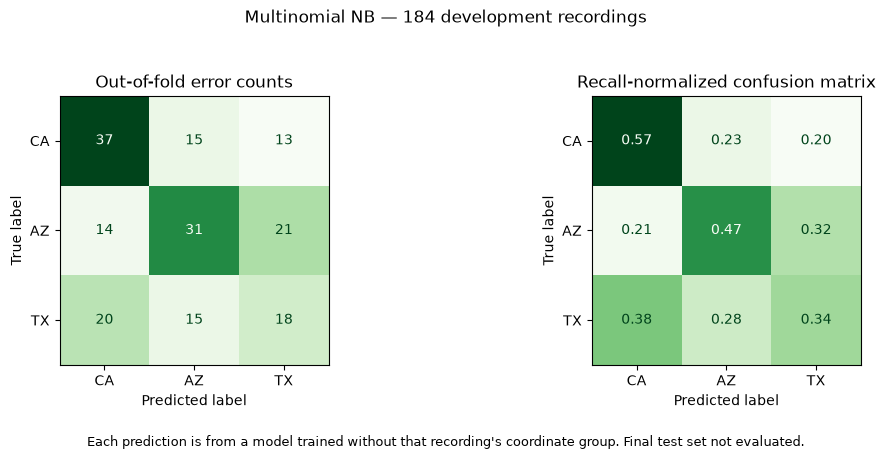


Diagnostics saved: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\naive_bayes\initial_cv_20261030T021759981307Z
No models refitted. No partitions or eligibility rules changed.


In [2]:
#  Diagnose existing out-of-fold predictions
# No refitting, tuning, or final-test evaluation.

import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

mnb_oof = oof_predictions.loc[
    oof_predictions["model"].eq("MNB: 3 bins, alpha=1")
].copy()

assert len(mnb_oof) == 184
assert mnb_oof["recording_id"].is_unique
mnb_oof["correct"] = mnb_oof["actual"].eq(mnb_oof["predicted"])

print("POOLED DEVELOPMENT CLASSIFICATION REPORT")
print(classification_report(
    mnb_oof["actual"], mnb_oof["predicted"],
    labels=CLASSES, digits=3, zero_division=0,
))

# Per-class recall exposes which states fail in each fold.
class_diagnostics = (
    mnb_oof.groupby(["validation_fold", "actual"])
    .agg(
        recordings=("recording_id", "size"),
        location_groups=("location_group", "nunique"),
        correct=("correct", "sum"),
        recall=("correct", "mean"),
    )
    .reset_index()
)

print("\nRECALL BY VALIDATION FOLD AND STATE")
print(class_diagnostics.pivot(
    index="validation_fold", columns="actual", values="recall"
).round(3).to_string())

group_diagnostics = (
    mnb_oof.groupby(["validation_fold", "actual", "location_group"])
    .agg(
        recordings=("recording_id", "size"),
        correct=("correct", "sum"),
        accuracy=("correct", "mean"),
    )
    .reset_index()
)
group_diagnostics["errors"] = (
    group_diagnostics["recordings"] - group_diagnostics["correct"]
)

print("\nLARGEST CONTRIBUTORS TO ERROR COUNTS")
print(
    group_diagnostics.sort_values(
        ["errors", "recordings"], ascending=False
    ).head(12).round(3).to_string(index=False)
)

# Diagnostic only: each location contributes equally within its true state.
# This is different from the primary recording-level macro-F1.
print("\nEQUAL-LOCATION MEAN ACCURACY WITHIN EACH STATE")
print(
    group_diagnostics.groupby("actual")["accuracy"]
    .agg(["mean", "count"])
    .rename(columns={"count": "location_groups"})
    .round(3).to_string()
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, normalization, title, value_format in [
    (axes[0], None, "Out-of-fold error counts", "d"),
    (axes[1], "true", "Recall-normalized confusion matrix", ".2f"),
]:
    matrix = confusion_matrix(
        mnb_oof["actual"], mnb_oof["predicted"],
        labels=CLASSES, normalize=normalization,
    )
    ConfusionMatrixDisplay(
        confusion_matrix=matrix, display_labels=CLASSES
    ).plot(
        ax=ax, cmap="Greens", colorbar=False,
        values_format=value_format,
    )
    ax.set_title(title)

fig.suptitle("Multinomial NB — 184 development recordings")
fig.text(
    0.5, 0.01,
    "Each prediction is from a model trained without that recording's "
    "coordinate group. Final test set not evaluated.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=[0, 0.06, 1, 0.94])
fig.savefig(nb_run_dir / "initial_oof_confusion_matrices.png", dpi=180)
plt.show()
plt.close(fig)

class_diagnostics.to_csv(
    nb_run_dir / "initial_oof_class_diagnostics.csv", index=False
)
group_diagnostics.to_csv(
    nb_run_dir / "initial_oof_group_diagnostics.csv", index=False
)

print("\nDiagnostics saved:", nb_run_dir)
print("No models refitted. No partitions or eligibility rules changed.")

In [3]:
#  Prespecified MNB search: 3/5 bins × alpha 0.1/1/10
# Same development folds; no final-test access.

from itertools import product

settings = list(product([3, 5], [0.1, 1.0, 10.0]))
search_rows = []
search_predictions = []

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
mnb_search_dir = (
    PROJECT_ROOT / "data/processed/supervised/v1/naive_bayes"
    / f"mnb_search_{stamp}"
)
mnb_search_dir.mkdir(parents=True, exist_ok=False)

# Save the search rules before fitting.
(mnb_search_dir / "search_protocol.json").write_text(
    json.dumps({
        "bins": [3, 5],
        "alpha": [0.1, 1.0, 10.0],
        "selection_metric": "Mean validation-fold macro-F1",
        "tie_rule": "Within 1e-12 of maximum: fewer bins, then larger alpha",
        "fold_manifest": artifacts["development_folds"],
        "final_test_evaluated": False,
    }, indent=2),
    encoding="utf-8",
)

for bins, alpha in settings:
    for fold in range(5):
        is_validation = fold_manifest["validation_fold"].eq(fold)
        train_idx = np.flatnonzero(~is_validation.to_numpy())
        validation_idx = np.flatnonzero(is_validation.to_numpy())

        assert set(
            fold_manifest.iloc[train_idx]["location_group"]
        ).isdisjoint(
            fold_manifest.iloc[validation_idx]["location_group"]
        )

        candidate = Pipeline([
            ("representation",
             make_representations(mnb_bins=bins)["multinomial_bins"]),
            ("classifier", MultinomialNB(alpha=alpha, fit_prior=True)),
        ])

        candidate.fit(X.iloc[train_idx], y.iloc[train_idx])
        predicted = candidate.predict(X.iloc[validation_idx])
        actual = y.iloc[validation_idx]

        search_rows.append({
            "bins": bins,
            "alpha": alpha,
            "fold": fold,
            "validation_n": len(validation_idx),
            "accuracy": accuracy_score(actual, predicted),
            "balanced_accuracy": balanced_accuracy_score(actual, predicted),
            "macro_f1": f1_score(
                actual, predicted, labels=CLASSES,
                average="macro", zero_division=0,
            ),
        })

        for position, prediction in zip(validation_idx, predicted):
            record = fold_manifest.iloc[position]
            search_predictions.append({
                "bins": bins,
                "alpha": alpha,
                "validation_fold": fold,
                "recording_id": record["recording_id"],
                "location_group": record["location_group"],
                "actual": record["model_state"],
                "predicted": prediction,
            })

    print(f"Completed: bins={bins}, alpha={alpha}")

mnb_search_folds = pd.DataFrame(search_rows)
mnb_search_oof = pd.DataFrame(search_predictions)

assert len(mnb_search_folds) == 30
assert mnb_search_oof.groupby(["bins", "alpha"]).size().eq(184).all()
assert not mnb_search_oof.duplicated(
    ["bins", "alpha", "recording_id"]
).any()

mnb_search_summary = (
    mnb_search_folds.groupby(["bins", "alpha"], as_index=False)
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        sd_macro_f1=("macro_f1", "std"),
        mean_accuracy=("accuracy", "mean"),
        mean_balanced_accuracy=("balanced_accuracy", "mean"),
    )
)

best_score = mnb_search_summary["mean_macro_f1"].max()
tied = mnb_search_summary.loc[
    np.isclose(
        mnb_search_summary["mean_macro_f1"],
        best_score, atol=1e-12, rtol=0,
    )
]
selected_row = tied.sort_values(
    ["bins", "alpha"], ascending=[True, False]
).iloc[0]

selected_mnb = {
    "bins": int(selected_row["bins"]),
    "alpha": float(selected_row["alpha"]),
    "fit_prior": True,
    "selection_mean_macro_f1": float(selected_row["mean_macro_f1"]),
    "final_test_evaluated": False,
}

print("\nSEARCH SUMMARY")
print(
    mnb_search_summary.sort_values(
        "mean_macro_f1", ascending=False
    ).round(4).to_string(index=False)
)

print("\nSELECTED CONFIGURATION")
print(json.dumps(selected_mnb, indent=2))

mnb_search_folds.to_csv(mnb_search_dir / "fold_metrics.csv", index=False)
mnb_search_summary.to_csv(mnb_search_dir / "search_summary.csv", index=False)
mnb_search_oof.to_csv(mnb_search_dir / "oof_predictions.csv", index=False)
(mnb_search_dir / "selected_configuration.json").write_text(
    json.dumps(selected_mnb, indent=2), encoding="utf-8"
)

print("\nSaved:", mnb_search_dir)
print("Final test set not evaluated.")

Completed: bins=3, alpha=0.1
Completed: bins=3, alpha=1.0
Completed: bins=3, alpha=10.0
Completed: bins=5, alpha=0.1
Completed: bins=5, alpha=1.0
Completed: bins=5, alpha=10.0

SEARCH SUMMARY
 bins  alpha  mean_macro_f1  sd_macro_f1  mean_accuracy  mean_balanced_accuracy
    5    1.0         0.4698       0.1425         0.4769                  0.4720
    3    0.1         0.4675       0.1632         0.4826                  0.4756
    3    1.0         0.4675       0.1632         0.4826                  0.4756
    5    0.1         0.4670       0.1465         0.4731                  0.4698
    5   10.0         0.4602       0.1298         0.4724                  0.4675
    3   10.0         0.4553       0.1665         0.4702                  0.4640

SELECTED CONFIGURATION
{
  "bins": 5,
  "alpha": 1.0,
  "fit_prior": true,
  "selection_mean_macro_f1": 0.4698080843238225,
  "final_test_evaluated": false
}

Saved: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supe

In [4]:
# Bounded Bernoulli/Gaussian NB comparisons
# Development CV only; no final-test evaluation.

from sklearn.naive_bayes import BernoulliNB, GaussianNB

variant_specs = [
    ("BernoulliNB", "alpha", value)
    for value in [0.1, 1.0, 10.0]
] + [
    ("GaussianNB", "var_smoothing", value)
    for value in [1e-11, 1e-9, 1e-7]
]

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
variant_dir = (
    PROJECT_ROOT / "data/processed/supervised/v1/naive_bayes"
    / f"nb_variants_{stamp}"
)
variant_dir.mkdir(parents=True, exist_ok=False)

(variant_dir / "search_protocol.json").write_text(
    json.dumps({
        "bernoulli_alpha": [0.1, 1.0, 10.0],
        "gaussian_var_smoothing": [1e-11, 1e-9, 1e-7],
        "selection_metric": "Mean validation-fold macro-F1",
        "tie_rule": "Within 1e-12 of maximum: larger smoothing value",
        "fold_manifest": artifacts["development_folds"],
        "final_test_evaluated": False,
    }, indent=2),
    encoding="utf-8",
)

variant_rows = []
variant_prediction_rows = []

for name, parameter, value in variant_specs:
    for fold in range(5):
        validation_mask = fold_manifest["validation_fold"].eq(fold)
        train_idx = np.flatnonzero(~validation_mask.to_numpy())
        validation_idx = np.flatnonzero(validation_mask.to_numpy())

        assert set(
            fold_manifest.iloc[train_idx]["location_group"]
        ).isdisjoint(
            fold_manifest.iloc[validation_idx]["location_group"]
        )

        templates = make_representations()

        if name == "BernoulliNB":
            representation = templates["bernoulli_indicators"]
            classifier = BernoulliNB(alpha=value, binarize=None)
        else:
            representation = templates["continuous"]
            classifier = GaussianNB(var_smoothing=value)

        candidate = Pipeline([
            ("representation", representation),
            ("classifier", classifier),
        ])

        candidate.fit(X.iloc[train_idx], y.iloc[train_idx])
        predicted = candidate.predict(X.iloc[validation_idx])
        actual = y.iloc[validation_idx]

        variant_rows.append({
            "model": name,
            "parameter": parameter,
            "value": value,
            "fold": fold,
            "accuracy": accuracy_score(actual, predicted),
            "balanced_accuracy": balanced_accuracy_score(actual, predicted),
            "macro_f1": f1_score(
                actual, predicted, labels=CLASSES,
                average="macro", zero_division=0,
            ),
        })

        for position, prediction in zip(validation_idx, predicted):
            record = fold_manifest.iloc[position]
            variant_prediction_rows.append({
                "model": name,
                "parameter": parameter,
                "value": value,
                "validation_fold": fold,
                "recording_id": record["recording_id"],
                "location_group": record["location_group"],
                "actual": record["model_state"],
                "predicted": prediction,
            })

    print(f"Completed: {name}, {parameter}={value:g}")

variant_folds = pd.DataFrame(variant_rows)
variant_oof = pd.DataFrame(variant_prediction_rows)

assert len(variant_folds) == 30
assert variant_oof.groupby(["model", "value"]).size().eq(184).all()
assert not variant_oof.duplicated(
    ["model", "value", "recording_id"]
).any()

variant_summary = (
    variant_folds.groupby(["model", "parameter", "value"], as_index=False)
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        sd_macro_f1=("macro_f1", "std"),
        mean_accuracy=("accuracy", "mean"),
        mean_balanced_accuracy=("balanced_accuracy", "mean"),
    )
)

selected_variants = {}

for name, rows in variant_summary.groupby("model"):
    best = rows["mean_macro_f1"].max()
    tied = rows.loc[np.isclose(
        rows["mean_macro_f1"], best, atol=1e-12, rtol=0
    )]
    chosen = tied.sort_values("value", ascending=False).iloc[0]

    selected_variants[name] = {
        "parameter": chosen["parameter"],
        "value": float(chosen["value"]),
        "selection_mean_macro_f1": float(chosen["mean_macro_f1"]),
    }

print("\nVARIANT SEARCH SUMMARY")
print(
    variant_summary.sort_values(
        ["model", "mean_macro_f1"], ascending=[True, False]
    ).to_string(index=False, float_format=lambda value: f"{value:.4g}")
)

print("\nSELECTED VARIANTS")
print(json.dumps(selected_variants, indent=2))

variant_folds.to_csv(variant_dir / "fold_metrics.csv", index=False)
variant_summary.to_csv(variant_dir / "search_summary.csv", index=False)
variant_oof.to_csv(variant_dir / "oof_predictions.csv", index=False)
(variant_dir / "selected_configurations.json").write_text(
    json.dumps(selected_variants, indent=2), encoding="utf-8"
)

print("\nSaved:", variant_dir)
print("Final test set not evaluated.")

Completed: BernoulliNB, alpha=0.1
Completed: BernoulliNB, alpha=1
Completed: BernoulliNB, alpha=10
Completed: GaussianNB, var_smoothing=1e-11
Completed: GaussianNB, var_smoothing=1e-09
Completed: GaussianNB, var_smoothing=1e-07

VARIANT SEARCH SUMMARY
      model     parameter  value  mean_macro_f1  sd_macro_f1  mean_accuracy  mean_balanced_accuracy
BernoulliNB         alpha    0.1         0.4568       0.1279         0.4773                    0.47
BernoulliNB         alpha      1         0.4568       0.1279         0.4773                    0.47
BernoulliNB         alpha     10         0.4519        0.131         0.4735                  0.4626
 GaussianNB var_smoothing  1e-11         0.4184      0.08403         0.4357                  0.4303
 GaussianNB var_smoothing  1e-07         0.3333      0.05729         0.3838                  0.3698
 GaussianNB var_smoothing  1e-09         0.3272      0.08363         0.3822                  0.3699

SELECTED VARIANTS
{
  "BernoulliNB": {
    "par

SELECTED-PIPELINE DEVELOPMENT SUMMARY
         model  pooled_oof_accuracy  pooled_oof_balanced_accuracy  pooled_oof_macro_f1
  Bernoulli NB                0.473                         0.464                0.464
   Gaussian NB                0.440                         0.439                0.438
Multinomial NB                0.462                         0.459                0.459


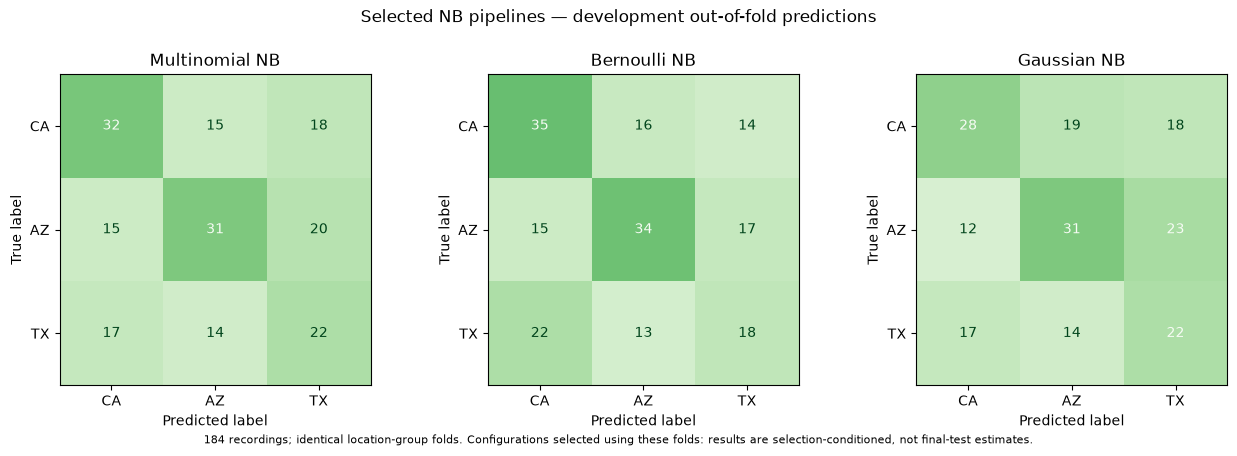


Saved NB checkpoint: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\naive_bayes\selected_checkpoint_20261030T023553086818Z
No models refitted. Final test remains unevaluated.


In [5]:
#  Consolidate selected NB development results
# Reuses saved-in-memory OOF predictions. No fitting or final-test access.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

selected_prediction_parts = []

# Selected Multinomial NB.
chosen_mnb = mnb_search_oof.loc[
    mnb_search_oof["bins"].eq(selected_mnb["bins"])
    & mnb_search_oof["alpha"].eq(selected_mnb["alpha"])
].copy()
chosen_mnb["model"] = "Multinomial NB"
selected_prediction_parts.append(chosen_mnb)

# Exact comparisons avoid conflating very small smoothing values.
for name, label in [
    ("BernoulliNB", "Bernoulli NB"),
    ("GaussianNB", "Gaussian NB"),
]:
    chosen = variant_oof.loc[
        variant_oof["model"].eq(name)
        & variant_oof["value"].eq(selected_variants[name]["value"])
    ].copy()
    chosen["model"] = label
    selected_prediction_parts.append(chosen)

prediction_columns = [
    "model", "recording_id", "location_group",
    "validation_fold", "actual", "predicted",
]
selected_nb_oof = pd.concat(
    [part[prediction_columns] for part in selected_prediction_parts],
    ignore_index=True,
)

assert selected_nb_oof.groupby("model").size().eq(184).all()
assert not selected_nb_oof.duplicated(["model", "recording_id"]).any()

summary_rows = []
for name, rows in selected_nb_oof.groupby("model"):
    summary_rows.append({
        "model": name,
        "pooled_oof_accuracy": accuracy_score(rows["actual"], rows["predicted"]),
        "pooled_oof_balanced_accuracy": balanced_accuracy_score(
            rows["actual"], rows["predicted"]
        ),
        "pooled_oof_macro_f1": f1_score(
            rows["actual"], rows["predicted"],
            labels=CLASSES, average="macro", zero_division=0,
        ),
    })

selected_nb_summary = pd.DataFrame(summary_rows)
print("SELECTED-PIPELINE DEVELOPMENT SUMMARY")
print(selected_nb_summary.round(3).to_string(index=False))

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
nb_checkpoint_dir = (
    PROJECT_ROOT / "data/processed/supervised/v1/naive_bayes"
    / f"selected_checkpoint_{stamp}"
)
nb_checkpoint_dir.mkdir(parents=True, exist_ok=False)

order = ["Multinomial NB", "Bernoulli NB", "Gaussian NB"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))

for ax, name in zip(axes, order):
    rows = selected_nb_oof.loc[selected_nb_oof["model"].eq(name)]
    matrix = confusion_matrix(
        rows["actual"], rows["predicted"], labels=CLASSES
    )
    assert matrix.sum() == 184

    ConfusionMatrixDisplay(matrix, display_labels=CLASSES).plot(
        ax=ax, cmap="Greens", colorbar=False, values_format="d",
        im_kw={"vmin": 0, "vmax": 66},
    )
    ax.set_title(name)

fig.suptitle("Selected NB pipelines — development out-of-fold predictions")
fig.text(
    0.5, 0.015,
    "184 recordings; identical location-group folds. Configurations selected "
    "using these folds: results are selection-conditioned, not final-test estimates.",
    ha="center", fontsize=8,
)
fig.tight_layout(rect=[0, 0.07, 1, 0.94])
fig.savefig(
    nb_checkpoint_dir / "selected_nb_oof_confusion_matrices.png",
    dpi=180, bbox_inches="tight",
)
plt.show()
plt.close(fig)

selected_nb_oof.to_csv(
    nb_checkpoint_dir / "selected_oof_predictions.csv", index=False
)
selected_nb_summary.to_csv(
    nb_checkpoint_dir / "selected_oof_summary.csv", index=False
)

(nb_checkpoint_dir / "selected_models.json").write_text(
    json.dumps({
        "MultinomialNB": selected_mnb,
        "BernoulliNB": selected_variants["BernoulliNB"],
        "GaussianNB": selected_variants["GaussianNB"],
        "feature_allowlist": feature_names,
        "fold_manifest": artifacts["development_folds"],
        "mnb_search_directory": str(mnb_search_dir.relative_to(PROJECT_ROOT)),
        "variant_search_directory": str(variant_dir.relative_to(PROJECT_ROOT)),
        "status": "Selected on development CV; final evaluation pending",
        "final_test_evaluated": False,
    }, indent=2),
    encoding="utf-8",
)

print("\nSaved NB checkpoint:", nb_checkpoint_dir)
print("No models refitted. Final test remains unevaluated.")

In [6]:
#  Verify a worked Multinomial NB prediction
# Educational refit of the selected configuration; no tuning or final test.

from scipy.special import logsumexp

validation_mask = fold_manifest["validation_fold"].eq(0)
train_idx = np.flatnonzero(~validation_mask.to_numpy())
validation_idx = np.flatnonzero(validation_mask.to_numpy())

example_position = validation_idx[0]  # Fixed, outcome-independent selection
example_id = fold_manifest.iloc[example_position]["recording_id"]

example_pipeline = Pipeline([
    ("representation", make_representations(
        mnb_bins=selected_mnb["bins"]
    )["multinomial_bins"]),
    ("classifier", MultinomialNB(
        alpha=selected_mnb["alpha"], fit_prior=True
    )),
])
example_pipeline.fit(X.iloc[train_idx], y.iloc[train_idx])

transformer = example_pipeline.named_steps["representation"]
classifier = example_pipeline.named_steps["classifier"]

encoded = transformer.transform(X.iloc[[example_position]])
encoded_row = (
    encoded.toarray().ravel()
    if hasattr(encoded, "toarray") else np.asarray(encoded).ravel()
)
token_names = transformer.get_feature_names_out(feature_names)
active = np.flatnonzero(encoded_row)

assert len(active) == 50
assert np.all(encoded_row[active] == 1)

# MNB: score(c) = log P(c) + sum_j x_j log P(token_j | c)
log_likelihood = classifier.feature_log_prob_ @ encoded_row
manual_scores = classifier.class_log_prior_ + log_likelihood
manual_probabilities = np.exp(manual_scores - logsumexp(manual_scores))

library_probabilities = example_pipeline.predict_proba(
    X.iloc[[example_position]]
)[0]
assert np.allclose(manual_probabilities, library_probabilities)

predicted_class = classifier.classes_[np.argmax(manual_scores)]
assert predicted_class == example_pipeline.predict(
    X.iloc[[example_position]]
)[0]

# Confirm this reproduces the stored selected-model OOF prediction.
stored_prediction = selected_nb_oof.loc[
    selected_nb_oof["model"].eq("Multinomial NB")
    & selected_nb_oof["recording_id"].eq(example_id),
    "predicted",
]
assert len(stored_prediction) == 1
assert predicted_class == stored_prediction.iloc[0]

score_table = pd.DataFrame({
    "class": classifier.classes_,
    "training_recordings": classifier.class_count_.astype(int),
    "log_prior": classifier.class_log_prior_,
    "summed_log_likelihood": log_likelihood,
    "total_log_score": manual_scores,
    "model_probability": manual_probabilities,
})

print("WORKED VALIDATION EXAMPLE")
print("Recording ID:", example_id)
print("Recorded state:", y.iloc[example_position])
print("Predicted state:", predicted_class)
print("Active tokens:", len(active))
print(score_table.round(5).to_string(index=False))

# Full token contributions make the calculation reproducible.
token_contributions = pd.DataFrame({
    "token": token_names[active],
    **{
        f"log_likelihood_{label}": classifier.feature_log_prob_[i, active]
        for i, label in enumerate(classifier.classes_)
    },
})

# Demonstrate smoothing using a real training token count.
counts = classifier.feature_count_
zero_positions = np.argwhere(counts == 0)

if len(zero_positions):
    class_index, token_index = zero_positions[0]
    example_type = "Observed zero-count class/token pair"
else:
    class_index, token_index = np.unravel_index(np.argmin(counts), counts.shape)
    example_type = "Lowest-count pair; no zero-count pair exists in this fit"

count = counts[class_index, token_index]
total_tokens = counts[class_index].sum()
vocabulary_size = counts.shape[1]
alpha = selected_mnb["alpha"]

unsmoothed = count / total_tokens
smoothed = (count + alpha) / (total_tokens + alpha * vocabulary_size)

assert np.isclose(
    smoothed,
    np.exp(classifier.feature_log_prob_[class_index, token_index]),
)

smoothing_example = {
    "example_type": example_type,
    "class": str(classifier.classes_[class_index]),
    "token": str(token_names[token_index]),
    "training_count": float(count),
    "total_class_tokens": float(total_tokens),
    "vocabulary_size": int(vocabulary_size),
    "alpha": float(alpha),
    "unsmoothed_probability": float(unsmoothed),
    "smoothed_probability": float(smoothed),
}

print("\nSMOOTHING EXAMPLE")
print(json.dumps(smoothing_example, indent=2))

example_dir = nb_checkpoint_dir / (
    "worked_example_"
    + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
)
example_dir.mkdir(parents=True, exist_ok=False)

score_table.to_csv(example_dir / "class_score_calculation.csv", index=False)
token_contributions.to_csv(
    example_dir / "active_token_contributions.csv", index=False
)
(example_dir / "example_details.json").write_text(
    json.dumps({
        "recording_id": str(example_id),
        "validation_fold": 0,
        "actual": str(y.iloc[example_position]),
        "predicted": str(predicted_class),
        "smoothing": smoothing_example,
        "manual_calculation_matches_sklearn": True,
        "probabilities_calibrated": False,
    }, indent=2),
    encoding="utf-8",
)

print("\nSaved:", example_dir)
print("Manual calculation matches sklearn and the stored OOF prediction.")

WORKED VALIDATION EXAMPLE
Recording ID: 1080405
Recorded state: AZ
Predicted state: AZ
Active tokens: 50
class  training_recordings  log_prior  summed_log_likelihood  total_log_score  model_probability
   AZ                   58   -0.95019             -275.07567       -276.02586            0.99124
   CA                   52   -1.05939             -280.50715       -281.56654            0.00389
   TX                   40   -1.32176             -280.01968       -281.34143            0.00487

SMOOTHING EXAMPLE
{
  "example_type": "Lowest-count pair; no zero-count pair exists in this fit",
  "class": "CA",
  "token": "ndsi_ratio_ba_mean_3.0",
  "training_count": 2.0,
  "total_class_tokens": 2600.0,
  "vocabulary_size": 250,
  "alpha": 1.0,
  "unsmoothed_probability": 0.0007692307692307692,
  "smoothed_probability": 0.0010526315789473684
}

Saved: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\naive_bayes\selected_checkpoint_20261030T023553086818Z\

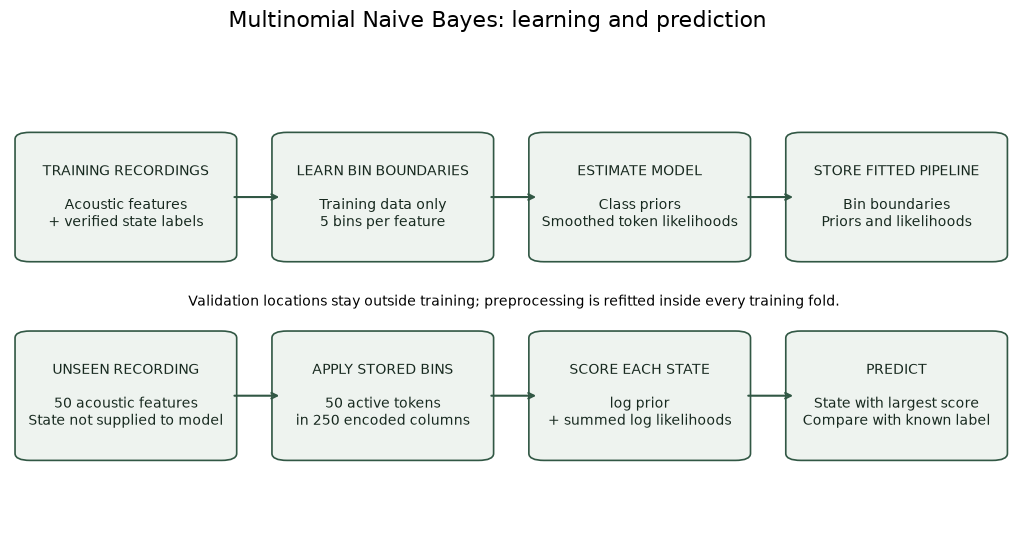

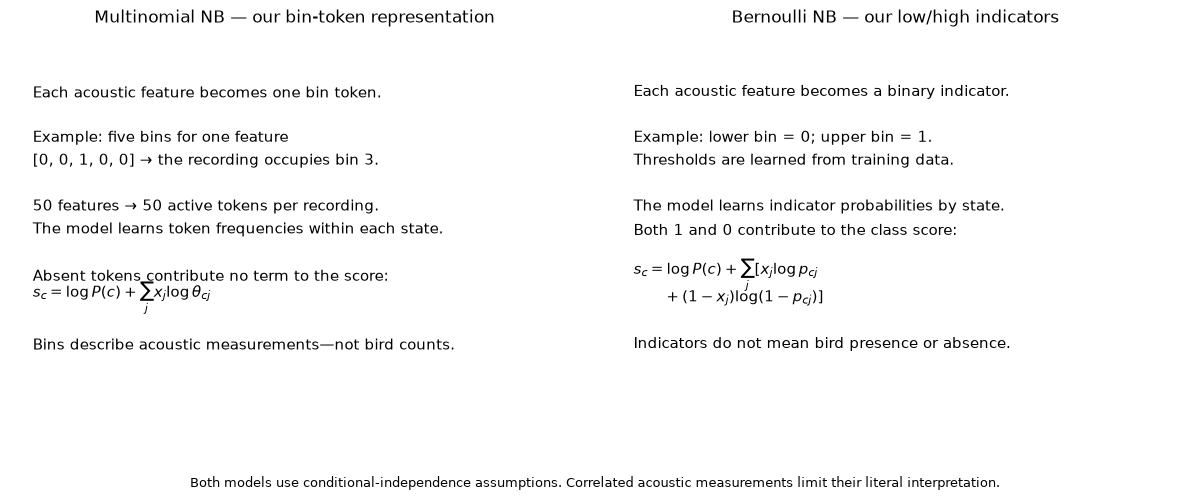

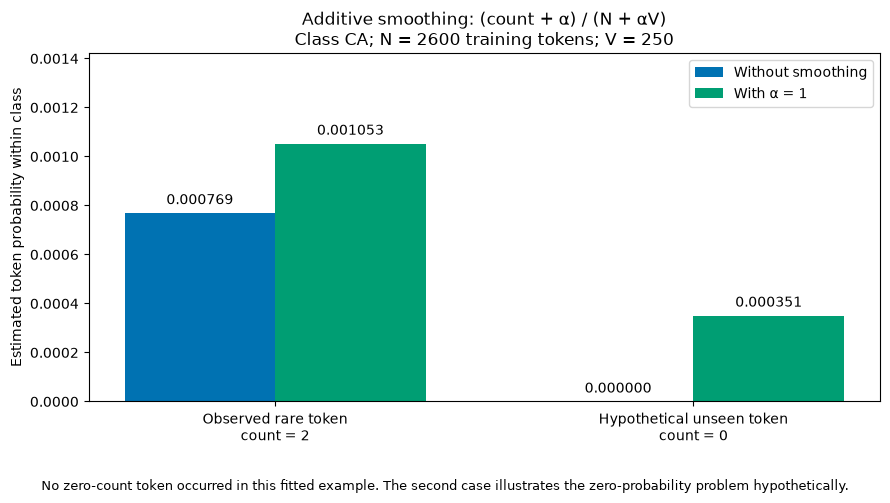

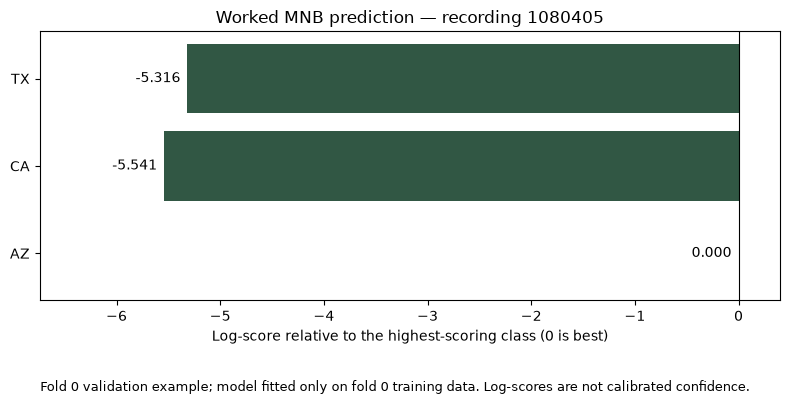

Saved teaching figures: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\naive_bayes\selected_checkpoint_20261030T023553086818Z\teaching_figures_20261030T024546287759Z
No models fitted. No final-test evaluation.


In [7]:
#  Cell 7
# Teaching visuals for NB Overview and the worked prediction.
# No fitting, tuning, or test evaluation.

from matplotlib.patches import FancyBboxPatch

viz_dir = nb_checkpoint_dir / (
    "teaching_figures_"
    + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
)
viz_dir.mkdir(parents=True, exist_ok=False)

def box(ax, x, y, width, height, text, face="#eef3ef"):
    patch = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.015",
        linewidth=1.2, edgecolor="#315744", facecolor=face,
    )
    ax.add_patch(patch)
    ax.text(
        x + width / 2, y + height / 2, text,
        ha="center", va="center", fontsize=10, color="#17291f",
    )

# 1. How training and prediction work.
fig, ax = plt.subplots(figsize=(13, 6))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

positions = [0.02, 0.275, 0.53, 0.785]
training_text = [
    "TRAINING RECORDINGS\n\nAcoustic features\n+ verified state labels",
    "LEARN BIN BOUNDARIES\n\nTraining data only\n5 bins per feature",
    "ESTIMATE MODEL\n\nClass priors\nSmoothed token likelihoods",
    "STORE FITTED PIPELINE\n\nBin boundaries\nPriors and likelihoods",
]
prediction_text = [
    "UNSEEN RECORDING\n\n50 acoustic features\nState not supplied to model",
    "APPLY STORED BINS\n\n50 active tokens\nin 250 encoded columns",
    "SCORE EACH STATE\n\nlog prior\n+ summed log likelihoods",
    "PREDICT\n\nState with largest score\nCompare with known label",
]

for y_position, texts in [(0.60, training_text), (0.17, prediction_text)]:
    for x, text in zip(positions, texts):
        box(ax, x, y_position, 0.19, 0.25, text)
    for x in positions[:-1]:
        ax.annotate(
            "", xy=(x + 0.25, y_position + 0.125),
            xytext=(x + 0.20, y_position + 0.125),
            arrowprops={"arrowstyle": "->", "color": "#315744", "lw": 1.5},
        )

ax.text(
    0.5, 0.49,
    "Validation locations stay outside training; preprocessing is refitted "
    "inside every training fold.",
    ha="center", fontsize=10,
)
fig.suptitle("Multinomial Naive Bayes: learning and prediction", fontsize=16)
fig.savefig(viz_dir / "nb_training_prediction.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# 2. Explain the two required NB variants.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax in axes:
    ax.axis("off")

axes[0].set_title("Multinomial NB — our bin-token representation", fontsize=12)
axes[0].text(
    0.04, 0.88,
    "Each acoustic feature becomes one bin token.\n\n"
    "Example: five bins for one feature\n"
    "[0, 0, 1, 0, 0] → the recording occupies bin 3.\n\n"
    "50 features → 50 active tokens per recording.\n"
    "The model learns token frequencies within each state.\n\n"
    "Absent tokens contribute no term to the score:\n"
    r"$s_c=\log P(c)+\sum_j x_j\log\theta_{cj}$"
    "\n\nBins describe acoustic measurements—not bird counts.",
    transform=axes[0].transAxes, va="top", fontsize=11, linespacing=1.5,
)
axes[1].set_title("Bernoulli NB — our low/high indicators", fontsize=12)
axes[1].text(
    0.04, 0.88,
    "Each acoustic feature becomes a binary indicator.\n\n"
    "Example: lower bin = 0; upper bin = 1.\n"
    "Thresholds are learned from training data.\n\n"
    "The model learns indicator probabilities by state.\n"
    "Both 1 and 0 contribute to the class score:\n\n"
    r"$s_c=\log P(c)+\sum_j[x_j\log p_{cj}$"
    "\n"
    r"$\qquad +(1-x_j)\log(1-p_{cj})]$"
    "\n\nIndicators do not mean bird presence or absence.",
    transform=axes[1].transAxes, va="top", fontsize=11, linespacing=1.5,
)
fig.text(
    0.5, 0.015,
    "Both models use conditional-independence assumptions. "
    "Correlated acoustic measurements limit their literal interpretation.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=[0, 0.07, 1, 1])
fig.savefig(viz_dir / "multinomial_vs_bernoulli.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# 3. Actual rare-token smoothing versus a labeled hypothetical zero count.
s = smoothing_example
N = s["total_class_tokens"]
V = s["vocabulary_size"]
alpha = s["alpha"]
observed_count = s["training_count"]

cases = [
    f"Observed rare token\ncount = {observed_count:g}",
    "Hypothetical unseen token\ncount = 0",
]
unsmoothed = np.array([observed_count / N, 0.0])
smoothed = np.array([
    (observed_count + alpha) / (N + alpha * V),
    alpha / (N + alpha * V),
])

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(2)
bars_a = ax.bar(x - 0.18, unsmoothed, 0.36, label="Without smoothing",
                color="#0072B2")
bars_b = ax.bar(x + 0.18, smoothed, 0.36, label=f"With α = {alpha:g}",
                color="#009E73")

ax.bar_label(bars_a, labels=[f"{v:.6f}" for v in unsmoothed], padding=4)
ax.bar_label(bars_b, labels=[f"{v:.6f}" for v in smoothed], padding=4)
ax.set_xticks(x, cases)
ax.set_ylabel("Estimated token probability within class")
ax.set_ylim(0, smoothed.max() * 1.35)
ax.set_title(
    f"Additive smoothing: (count + α) / (N + αV)\n"
    f"Class {s['class']}; N = {N:g} training tokens; V = {V}"
)
ax.legend()
fig.text(
    0.5, 0.01,
    "No zero-count token occurred in this fitted example. "
    "The second case illustrates the zero-probability problem hypothetically.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=[0, 0.07, 1, 1])
fig.savefig(viz_dir / "nb_smoothing.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# 4. Verified example: relative log-scores, not calibrated confidence.
plot_scores = score_table.copy()
plot_scores["relative_log_score"] = (
    plot_scores["total_log_score"] - plot_scores["total_log_score"].max()
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(
    plot_scores["class"], plot_scores["relative_log_score"],
    color="#315744",
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Log-score relative to the highest-scoring class (0 is best)")
ax.set_title(f"Worked MNB prediction — recording {example_id}")
for position, value in enumerate(plot_scores["relative_log_score"]):
    ax.annotate(
        f"{value:.3f}", (value, position),
        xytext=(-5, 0), textcoords="offset points",
        ha="right", va="center",
    )
ax.set_xlim(plot_scores["relative_log_score"].min() - 1.2, 0.4)
fig.text(
    0.5, 0.01,
    "Fold 0 validation example; model fitted only on fold 0 training data. "
    "Log-scores are not calibrated confidence.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=[0, 0.09, 1, 1])
fig.savefig(viz_dir / "nb_worked_prediction.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved teaching figures:", viz_dir)
print("No models fitted. No final-test evaluation.")

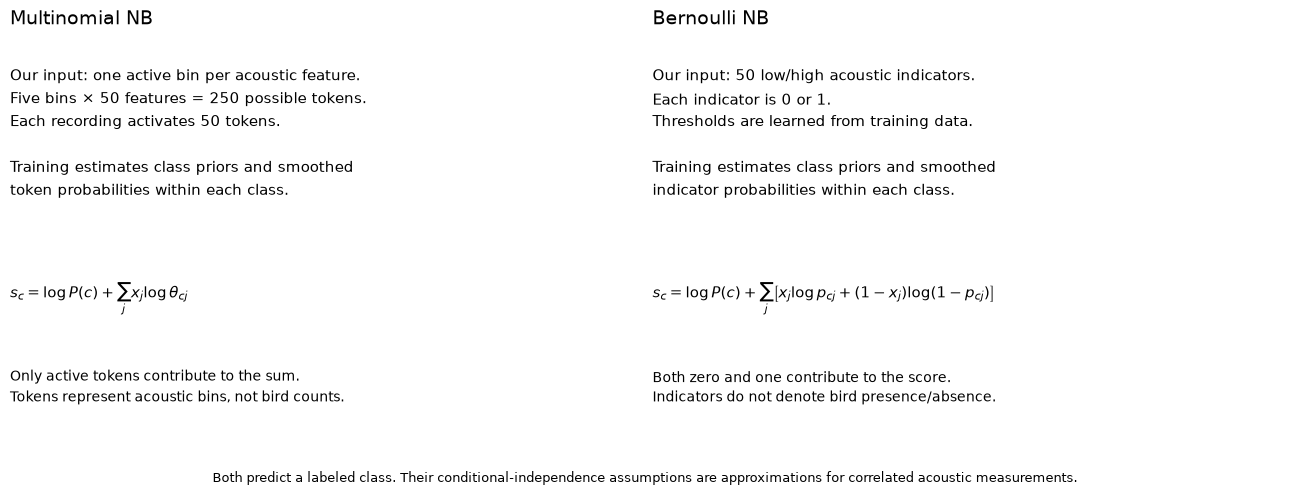

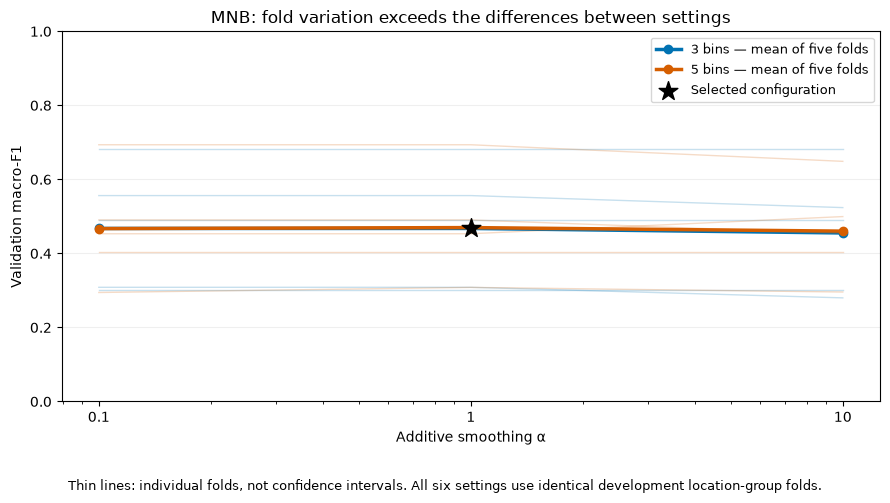

Saved figures and conclusions draft: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\naive_bayes\selected_checkpoint_20261030T023553086818Z\teaching_figures_20261030T024546287759Z
Use multinomial_vs_bernoulli_v2.png instead of the earlier comparison.
No models fitted. Final test remains unevaluated.


In [8]:
# Repair explanation figure, visualize search, draft conclusions
# Uses existing results only. No fitting or final-test evaluation.

# 1. Cleaner comparison with separately positioned equations.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

panels = [
    (
        "Multinomial NB",
        "Our input: one active bin per acoustic feature.\n"
        "Five bins × 50 features = 250 possible tokens.\n"
        "Each recording activates 50 tokens.\n\n"
        "Training estimates class priors and smoothed\n"
        "token probabilities within each class.",
        r"$s_c=\log P(c)+\sum_j x_j\log\theta_{cj}$",
        "Only active tokens contribute to the sum.\n"
        "Tokens represent acoustic bins, not bird counts.",
    ),
    (
        "Bernoulli NB",
        "Our input: 50 low/high acoustic indicators.\n"
        "Each indicator is 0 or 1.\n"
        "Thresholds are learned from training data.\n\n"
        "Training estimates class priors and smoothed\n"
        "indicator probabilities within each class.",
        r"$s_c=\log P(c)+\sum_j\left[x_j\log p_{cj}"
        r"+(1-x_j)\log(1-p_{cj})\right]$",
        "Both zero and one contribute to the score.\n"
        "Indicators do not denote bird presence/absence.",
    ),
]

for ax, (title, description, equation, interpretation) in zip(axes, panels):
    ax.axis("off")
    ax.set_title(title, fontsize=14, loc="left")
    ax.text(0, 0.92, description, transform=ax.transAxes,
            va="top", fontsize=11, linespacing=1.5)
    ax.text(0, 0.38, equation, transform=ax.transAxes,
            va="top", fontsize=11)
    ax.text(0, 0.17, interpretation, transform=ax.transAxes,
            va="top", fontsize=10, linespacing=1.5)

fig.text(
    0.5, 0.025,
    "Both predict a labeled class. Their conditional-independence assumptions "
    "are approximations for correlated acoustic measurements.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=[0, 0.09, 1, 1])
fig.savefig(
    viz_dir / "multinomial_vs_bernoulli_v2.png",
    dpi=180, bbox_inches="tight",
)
plt.show()
plt.close(fig)

# 2. Search sensitivity: thin lines are folds, thick lines are fold means.
fig, ax = plt.subplots(figsize=(9, 5))
colors = {3: "#0072B2", 5: "#D55E00"}

for bins in [3, 5]:
    subset = mnb_search_folds.loc[mnb_search_folds["bins"].eq(bins)]

    for fold, rows in subset.groupby("fold"):
        rows = rows.sort_values("alpha")
        ax.plot(
            rows["alpha"], rows["macro_f1"],
            color=colors[bins], alpha=0.22, linewidth=1,
        )

    means = (
        mnb_search_summary.loc[mnb_search_summary["bins"].eq(bins)]
        .sort_values("alpha")
    )
    ax.plot(
        means["alpha"], means["mean_macro_f1"],
        color=colors[bins], marker="o", linewidth=2.5,
        label=f"{bins} bins — mean of five folds",
    )

ax.scatter(
    selected_mnb["alpha"], selected_mnb["selection_mean_macro_f1"],
    marker="*", s=200, color="black", zorder=5,
    label="Selected configuration",
)
ax.set_xscale("log")
ax.set_xticks([0.1, 1, 10], labels=["0.1", "1", "10"])
ax.set_ylim(0, 1)
ax.set_xlabel("Additive smoothing α")
ax.set_ylabel("Validation macro-F1")
ax.set_title("MNB: fold variation exceeds the differences between settings")
ax.grid(axis="y", alpha=0.2)
ax.legend(fontsize=9)

fig.text(
    0.5, 0.01,
    "Thin lines: individual folds, not confidence intervals. "
    "All six settings use identical development location-group folds.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=[0, 0.07, 1, 1])
fig.savefig(viz_dir / "mnb_search_sensitivity.png", dpi=180, bbox_inches="tight")
fig.savefig(viz_dir / "mnb_search_sensitivity.svg", bbox_inches="tight")
plt.show()
plt.close(fig)

mnb_search_folds.to_csv(
    viz_dir / "mnb_search_sensitivity_data.csv", index=False
)

# 3. Provisional interpretation: clearly separate selection from final results.
pooled = selected_nb_summary.set_index("model")
baseline_mean = fold_results.loc[
    fold_results["model"].eq("Prior baseline"), "macro_f1"
].mean()

conclusions = f"""# Naive Bayes — provisional development conclusions

Status: development analysis only. Final holdout evaluation is pending.

## Purpose
These classifiers predict verified regional labels from acoustic measurements.
The primary question is original Q7: How consistently do acoustic characteristics
distinguish different groups of recordings?

## Findings
The selected Multinomial NB pipeline uses five quantile bins per feature and
alpha = 1. Its mean-fold macro-F1 is
{selected_mnb['selection_mean_macro_f1']:.3f}, compared with
{baseline_mean:.3f} for the prior baseline.

The selected Bernoulli and Gaussian pipelines achieve mean-fold macro-F1 of
{selected_variants['BernoulliNB']['selection_mean_macro_f1']:.3f} and
{selected_variants['GaussianNB']['selection_mean_macro_f1']:.3f}, respectively.

Pooling the selected pipelines' development predictions gives macro-F1
{pooled.loc['Multinomial NB', 'pooled_oof_macro_f1']:.3f} for Multinomial NB and
{pooled.loc['Bernoulli NB', 'pooled_oof_macro_f1']:.3f} for Bernoulli NB.
The ranking differs because pooled and mean-fold metrics aggregate differently.
Selection remains based on the predefined mean-fold metric.

## Interpretation
Q7 is partially supported: acoustic measurements carry predictive information
relative to the tested baseline, but performance varies substantially between
held-out location groups. The small differences among smoothing/bin settings
do not resolve this variability.

For Q1, classification demonstrates some regional discrimination in this
selected collection; it does not identify a causal geographic mechanism or,
by itself, establish which physical acoustic characteristics explain it.

For Q6 and Q10, uneven species composition, geographic concentration, duration,
and recording conditions limit ecological interpretation. This is a selected
focal-recording collection, not a standardized biodiversity survey.

## Limits
These configurations were selected using the same development folds summarized
here. Their reported scores are selection-conditioned, not independent final
performance estimates. Location grouping does not guarantee separation of
nearby sites or recordists. Pipeline comparisons change both representation
and likelihood assumptions. Model probabilities have not been calibrated.

## Pending before final conclusions
Evaluate frozen configurations on the reserved holdout; report class support,
confusion matrices, accuracy, macro-F1, and uncertainty under the planned
protocol. Complete the predefined quality sensitivity and feature-family
analyses where feasible, without tuning on final-test outcomes.
"""

(viz_dir / "nb_development_conclusions_draft.md").write_text(
    conclusions, encoding="utf-8"
)

print("Saved figures and conclusions draft:", viz_dir)
print("Use multinomial_vs_bernoulli_v2.png instead of the earlier comparison.")
print("No models fitted. Final test remains unevaluated.")

In [9]:
# Out-of-fold probability diagnostics
# Selected configurations, unchanged folds, no final-test access.

from sklearn.metrics import log_loss
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB, BernoulliNB, GaussianNB

# Alphabetical order matches sklearn's label ordering for log_loss.
PROB_CLASSES = np.array(["AZ", "CA", "TX"])
prob_columns = [f"p_{state}" for state in PROB_CLASSES]

probability_models = {
    "Prior baseline": DummyClassifier(strategy="prior"),

    "Multinomial NB": Pipeline([
        ("representation", make_representations(
            mnb_bins=selected_mnb["bins"]
        )["multinomial_bins"]),
        ("classifier", MultinomialNB(
            alpha=selected_mnb["alpha"], fit_prior=True
        )),
    ]),

    "Bernoulli NB": Pipeline([
        ("representation", make_representations()["bernoulli_indicators"]),
        ("classifier", BernoulliNB(
            alpha=selected_variants["BernoulliNB"]["value"],
            binarize=None,
        )),
    ]),

    "Gaussian NB": Pipeline([
        ("representation", make_representations()["continuous"]),
        ("classifier", GaussianNB(
            var_smoothing=selected_variants["GaussianNB"]["value"]
        )),
    ]),
}

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
probability_dir = (
    nb_checkpoint_dir / f"probability_diagnostics_{stamp}"
)
probability_dir.mkdir(parents=True, exist_ok=False)

(probability_dir / "protocol_amendment.json").write_text(
    json.dumps({
        "purpose": "Evaluate probability quality of selected NB pipelines",
        "timing": "Added after examining NB development classification results",
        "configurations": {
            "MultinomialNB": selected_mnb,
            **selected_variants,
        },
        "fold_manifest": artifacts["development_folds"],
        "brier_definition": "Mean over recordings of sum_c (p_c - y_c)^2",
        "probability_calibration_fitted": False,
        "additional_tuning": False,
        "final_test_evaluated": False,
        "limitation": "Configuration selection used these development folds.",
    }, indent=2),
    encoding="utf-8",
)

def probability_scores(actual, probabilities):
    actual = np.asarray(actual)
    one_hot = (actual[:, None] == PROB_CLASSES[None, :]).astype(float)
    return {
        "log_loss": log_loss(
            actual, probabilities, labels=PROB_CLASSES.tolist()
        ),
        "brier_sum": float(
            np.mean(np.sum((probabilities - one_hot) ** 2, axis=1))
        ),
    }

probability_rows = []
probability_fold_rows = []

for name, template in probability_models.items():
    for fold in range(5):
        validation_mask = fold_manifest["validation_fold"].eq(fold)
        train_idx = np.flatnonzero(~validation_mask.to_numpy())
        validation_idx = np.flatnonzero(validation_mask.to_numpy())

        assert set(
            fold_manifest.iloc[train_idx]["location_group"]
        ).isdisjoint(
            fold_manifest.iloc[validation_idx]["location_group"]
        )

        fitted = clone(template)
        fitted.fit(X.iloc[train_idx], y.iloc[train_idx])

        class_order = [
            list(fitted.classes_).index(state) for state in PROB_CLASSES
        ]
        probabilities = fitted.predict_proba(
            X.iloc[validation_idx]
        )[:, class_order]
        predicted = fitted.predict(X.iloc[validation_idx])

        assert np.isfinite(probabilities).all()
        assert ((probabilities >= 0) & (probabilities <= 1)).all()
        assert np.allclose(probabilities.sum(axis=1), 1)

        probability_fold_rows.append({
            "model": name,
            "fold": fold,
            "validation_n": len(validation_idx),
            **probability_scores(y.iloc[validation_idx], probabilities),
        })

        for position, prediction, probs in zip(
            validation_idx, predicted, probabilities
        ):
            record = fold_manifest.iloc[position]
            probability_rows.append({
                "model": name,
                "recording_id": record["recording_id"],
                "location_group": record["location_group"],
                "validation_fold": fold,
                "actual": record["model_state"],
                "predicted": prediction,
                **dict(zip(prob_columns, probs)),
            })

    print("Completed:", name)

probability_oof = pd.DataFrame(probability_rows)
probability_folds = pd.DataFrame(probability_fold_rows)

assert probability_oof.groupby("model").size().eq(184).all()
assert not probability_oof.duplicated(["model", "recording_id"]).any()

# Verify refits reproduce the previously saved NB classifications.
comparison = probability_oof.merge(
    selected_nb_oof[["model", "recording_id", "predicted"]],
    on=["model", "recording_id"],
    suffixes=("_new", "_saved"),
    validate="one_to_one",
)
assert len(comparison) == 3 * 184
assert comparison["predicted_new"].eq(comparison["predicted_saved"]).all()

summary_rows = []
for name, rows in probability_oof.groupby("model"):
    probs = rows[prob_columns].to_numpy()
    confident = probs.max(axis=1) >= 0.90
    correct = rows["actual"].eq(rows["predicted"]).to_numpy()

    summary_rows.append({
        "model": name,
        **probability_scores(rows["actual"], probs),
        "predictions_at_least_0.90": int(confident.sum()),
        "errors_at_least_0.90": int((confident & ~correct).sum()),
        "accuracy_at_least_0.90": (
            float(correct[confident].mean()) if confident.any() else np.nan
        ),
    })

probability_summary = pd.DataFrame(summary_rows)

print("\nMEAN AND SD OF FOLD SCORES — LOWER IS BETTER")
print(
    probability_folds.groupby("model")[["log_loss", "brier_sum"]]
    .agg(["mean", "std"]).round(4).to_string()
)

print("\nPOOLED OUT-OF-FOLD PROBABILITY DIAGNOSTICS")
print(probability_summary.round(4).to_string(index=False))

probability_oof.to_csv(probability_dir / "oof_probabilities.csv", index=False)
probability_folds.to_csv(probability_dir / "fold_scores.csv", index=False)
probability_summary.to_csv(probability_dir / "pooled_scores.csv", index=False)

print("\nSaved:", probability_dir)
print("NB classifications match earlier results.")
print("No calibrator fitted. Final test remains unevaluated.")

Completed: Prior baseline
Completed: Multinomial NB
Completed: Bernoulli NB
Completed: Gaussian NB

MEAN AND SD OF FOLD SCORES — LOWER IS BETTER
               log_loss         brier_sum        
                   mean     std      mean     std
model                                            
Bernoulli NB     2.1038  0.6585    0.8377  0.2061
Gaussian NB      3.3838  1.7539    0.9057  0.1848
Multinomial NB   2.7611  1.1264    0.8967  0.2809
Prior baseline   1.1246  0.0259    0.6836  0.0163

POOLED OUT-OF-FOLD PROBABILITY DIAGNOSTICS
         model  log_loss  brier_sum  predictions_at_least_0.90  errors_at_least_0.90  accuracy_at_least_0.90
  Bernoulli NB    2.1880     0.8587                         88                    42                  0.5227
   Gaussian NB    3.6259     0.9040                         87                    45                  0.4828
Multinomial NB    2.8756     0.9261                        113                    58                  0.4867
Prior baseline    1.1295 

TOP-LABEL RELIABILITY
         model      bin  recordings  location_groups  mean_probability  observed_accuracy  overconfidence_gap
  Bernoulli NB 0.4–<0.6          18               17             0.544              0.333               0.211
  Bernoulli NB 0.6–<0.8          41               40             0.703              0.463               0.240
  Bernoulli NB 0.8–<0.9          37               33             0.858              0.432               0.425
  Bernoulli NB    0.9–1          88               66             0.970              0.523               0.447
   Gaussian NB   0–<0.4           2                2             0.374              0.500              -0.126
   Gaussian NB 0.4–<0.6          35               33             0.511              0.371               0.140
   Gaussian NB 0.6–<0.8          32               30             0.715              0.469               0.246
   Gaussian NB 0.8–<0.9          28               27             0.856              0.357         

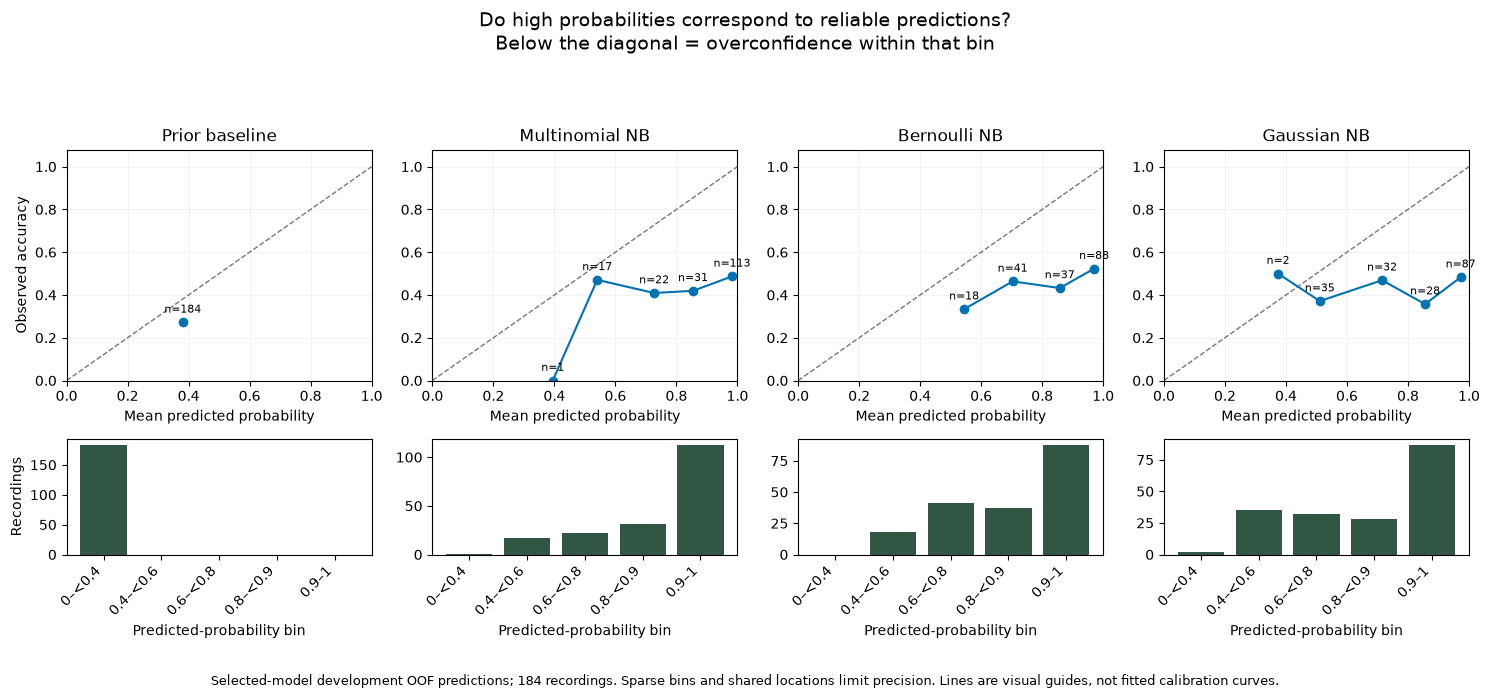


Saved: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\naive_bayes\selected_checkpoint_20261030T023553086818Z\probability_diagnostics_20261030T025842352733Z
No calibrator fitted; final test remains unevaluated.


In [10]:
#  Top-label reliability and confidence-bin support
# Existing development predictions only. No model/calibrator fitting.

reliability_data = probability_oof.copy()
reliability_data["confidence"] = (
    reliability_data[prob_columns].max(axis=1)
)
reliability_data["correct"] = (
    reliability_data["actual"].eq(reliability_data["predicted"])
).astype(int)

# Fixed bins chosen for interpretability, not optimized against results.
edges = np.array([0.0, 0.4, 0.6, 0.8, 0.9, 1.0])
bin_labels = ["0–<0.4", "0.4–<0.6", "0.6–<0.8", "0.8–<0.9", "0.9–1"]

# Exact 0.9 belongs in the final bin; exact 1.0 is included.
reliability_data["bin_index"] = np.minimum(
    np.searchsorted(
        edges[1:], reliability_data["confidence"], side="right"
    ),
    len(bin_labels) - 1,
)

reliability_table = (
    reliability_data.groupby(["model", "bin_index"], as_index=False)
    .agg(
        recordings=("recording_id", "size"),
        location_groups=("location_group", "nunique"),
        mean_probability=("confidence", "mean"),
        observed_accuracy=("correct", "mean"),
    )
)
reliability_table["bin"] = reliability_table["bin_index"].map(
    dict(enumerate(bin_labels))
)
reliability_table["overconfidence_gap"] = (
    reliability_table["mean_probability"]
    - reliability_table["observed_accuracy"]
)

print("TOP-LABEL RELIABILITY")
print(
    reliability_table[[
        "model", "bin", "recordings", "location_groups",
        "mean_probability", "observed_accuracy", "overconfidence_gap",
    ]].round(3).to_string(index=False)
)

models_order = [
    "Prior baseline", "Multinomial NB", "Bernoulli NB", "Gaussian NB"
]
fig, axes = plt.subplots(
    2, 4, figsize=(15, 7),
    gridspec_kw={"height_ratios": [2, 1]},
)

for column, name in enumerate(models_order):
    rows = (
        reliability_table.loc[reliability_table["model"].eq(name)]
        .sort_values("bin_index")
    )

    ax = axes[0, column]
    ax.plot([0, 1], [0, 1], "--", color="#777777", linewidth=1)
    ax.plot(
        rows["mean_probability"], rows["observed_accuracy"],
        color="#0072B2", marker="o", linewidth=1.5,
    )

    for row in rows.itertuples(index=False):
        ax.annotate(
            f"n={row.recordings}",
            (row.mean_probability, row.observed_accuracy),
            xytext=(0, 7), textcoords="offset points",
            ha="center", fontsize=8,
        )

    ax.set_title(name)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.08)
    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Observed accuracy" if column == 0 else "")
    ax.grid(alpha=0.15)

    support = rows.set_index("bin_index")["recordings"].reindex(
        range(len(bin_labels)), fill_value=0
    )
    axes[1, column].bar(
        range(len(bin_labels)), support, color="#315744"
    )
    axes[1, column].set_xticks(
        range(len(bin_labels)), bin_labels, rotation=45, ha="right"
    )
    axes[1, column].set_ylabel("Recordings" if column == 0 else "")
    axes[1, column].set_xlabel("Predicted-probability bin")

fig.suptitle(
    "Do high probabilities correspond to reliable predictions?\n"
    "Below the diagonal = overconfidence within that bin",
    fontsize=14,
)
fig.text(
    0.5, 0.015,
    "Selected-model development OOF predictions; 184 recordings. "
    "Sparse bins and shared locations limit precision. Lines are visual guides, "
    "not fitted calibration curves.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=[0, 0.06, 1, 0.92])
fig.savefig(
    probability_dir / "top_label_reliability.png",
    dpi=180, bbox_inches="tight",
)
fig.savefig(
    probability_dir / "top_label_reliability.svg",
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

reliability_table.to_csv(
    probability_dir / "top_label_reliability.csv", index=False
)

print("\nSaved:", probability_dir)
print("No calibrator fitted; final test remains unevaluated.")

In [11]:
#  Group-aware sigmoid calibration of selected MNB
# Fixed configuration and method; no final-test access.

from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
calibration_dir = (
    nb_checkpoint_dir / f"sigmoid_calibration_{stamp}"
)
calibration_dir.mkdir(parents=True, exist_ok=False)

(calibration_dir / "protocol.json").write_text(
    json.dumps({
        "base_model": selected_mnb,
        "calibration_method": "sigmoid",
        "outer_folds": artifacts["development_folds"],
        "inner_folds": 3,
        "inner_grouping": "Exact-coordinate location groups",
        "inner_seed": 42,
        "ensemble": False,
        "purpose": "Exploratory probability-quality comparison",
        "limitation": (
            "Base hyperparameters were selected using development folds; "
            "this is not fully nested model-selection evaluation."
        ),
        "final_test_evaluated": False,
    }, indent=2),
    encoding="utf-8",
)

calibrated_rows = []
inner_assignment_rows = []

for outer_fold in range(5):
    is_validation = fold_manifest["validation_fold"].eq(outer_fold)
    train_idx = np.flatnonzero(~is_validation.to_numpy())
    validation_idx = np.flatnonzero(is_validation.to_numpy())

    outer_training = fold_manifest.iloc[train_idx].reset_index(drop=True)
    outer_validation = fold_manifest.iloc[validation_idx]

    assert set(outer_training["location_group"]).isdisjoint(
        outer_validation["location_group"]
    )

    groups = (
        outer_training.groupby("location_group", as_index=False)
        .agg(
            state=("model_state", "first"),
            state_count=("model_state", "nunique"),
        )
        .sort_values("location_group")
        .reset_index(drop=True)
    )
    assert groups["state_count"].eq(1).all()

    splitter = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    inner_cv = []
    validation_coverage = np.zeros(len(outer_training), dtype=int)

    for inner_fold, (group_train_idx, group_validation_idx) in enumerate(
        splitter.split(groups["location_group"], groups["state"])
    ):
        inner_validation_groups = set(
            groups.iloc[group_validation_idx]["location_group"]
        )
        inner_mask = outer_training["location_group"].isin(
            inner_validation_groups
        ).to_numpy()

        inner_train_idx = np.flatnonzero(~inner_mask)
        inner_validation_idx = np.flatnonzero(inner_mask)

        assert set(
            outer_training.iloc[inner_train_idx]["model_state"]
        ) == set(PROB_CLASSES)
        assert set(
            outer_training.iloc[inner_validation_idx]["model_state"]
        ) == set(PROB_CLASSES)
        assert set(
            outer_training.iloc[inner_train_idx]["location_group"]
        ).isdisjoint(
            outer_training.iloc[inner_validation_idx]["location_group"]
        )

        inner_cv.append((inner_train_idx, inner_validation_idx))
        validation_coverage[inner_validation_idx] += 1

        for position in inner_validation_idx:
            row = outer_training.iloc[position]
            inner_assignment_rows.append({
                "outer_fold": outer_fold,
                "inner_validation_fold": inner_fold,
                "recording_id": row["recording_id"],
                "location_group": row["location_group"],
            })

    assert np.all(validation_coverage == 1)

    calibrated = CalibratedClassifierCV(
        estimator=clone(probability_models["Multinomial NB"]),
        method="sigmoid",
        cv=inner_cv,
        ensemble=False,
        n_jobs=1,
    )
    calibrated.fit(
        X.iloc[train_idx].reset_index(drop=True),
        y.iloc[train_idx].reset_index(drop=True),
    )

    class_order = [
        list(calibrated.classes_).index(state) for state in PROB_CLASSES
    ]
    probs = calibrated.predict_proba(
        X.iloc[validation_idx]
    )[:, class_order]
    predictions = calibrated.predict(X.iloc[validation_idx])

    assert np.isfinite(probs).all()
    assert np.allclose(probs.sum(axis=1), 1)

    for position, prediction, p in zip(validation_idx, predictions, probs):
        record = fold_manifest.iloc[position]
        calibrated_rows.append({
            "model": "MNB + sigmoid calibration",
            "recording_id": record["recording_id"],
            "location_group": record["location_group"],
            "validation_fold": outer_fold,
            "actual": record["model_state"],
            "predicted": prediction,
            **dict(zip(prob_columns, p)),
        })

    print(f"Completed outer fold {outer_fold}")

calibrated_oof = pd.DataFrame(calibrated_rows)
assert len(calibrated_oof) == 184
assert calibrated_oof["recording_id"].is_unique

raw_mnb = probability_oof.loc[
    probability_oof["model"].eq("Multinomial NB")
].copy()
assert set(raw_mnb["recording_id"]) == set(calibrated_oof["recording_id"])

calibration_comparison_oof = pd.concat(
    [raw_mnb, calibrated_oof], ignore_index=True
)

comparison_rows = []
for (name, fold), rows in calibration_comparison_oof.groupby(
    ["model", "validation_fold"]
):
    comparison_rows.append({
        "model": name,
        "fold": fold,
        **probability_scores(rows["actual"], rows[prob_columns].to_numpy()),
        "accuracy": accuracy_score(rows["actual"], rows["predicted"]),
        "macro_f1": f1_score(
            rows["actual"], rows["predicted"],
            labels=CLASSES, average="macro", zero_division=0,
        ),
    })

calibration_fold_scores = pd.DataFrame(comparison_rows)

print("\nMEAN DEVELOPMENT-FOLD SCORES")
print(
    calibration_fold_scores.groupby("model")[
        ["log_loss", "brier_sum", "accuracy", "macro_f1"]
    ].mean().round(4).to_string()
)

print("\nPAIRED FOLD LOG LOSS — LOWER IS BETTER")
print(calibration_fold_scores.pivot(
    index="fold", columns="model", values="log_loss"
).round(4).to_string())

calibration_comparison_oof.to_csv(
    calibration_dir / "raw_and_calibrated_oof.csv", index=False
)
calibration_fold_scores.to_csv(
    calibration_dir / "fold_metrics.csv", index=False
)
pd.DataFrame(inner_assignment_rows).to_csv(
    calibration_dir / "inner_fold_assignments.csv", index=False
)

print("\nSaved:", calibration_dir)
print("Final test remains unevaluated.")

Completed outer fold 0
Completed outer fold 1
Completed outer fold 2
Completed outer fold 3
Completed outer fold 4

MEAN DEVELOPMENT-FOLD SCORES
                           log_loss  brier_sum  accuracy  macro_f1
model                                                             
MNB + sigmoid calibration    1.1083     0.6719    0.4366    0.3930
Multinomial NB               2.7611     0.8967    0.4769    0.4698

PAIRED FOLD LOG LOSS — LOWER IS BETTER
model  MNB + sigmoid calibration  Multinomial NB
fold                                            
0                         1.0909          3.1354
1                         1.0777          0.9673
2                         1.1830          3.8388
3                         1.1471          3.4310
4                         1.0427          2.4331

Saved: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\naive_bayes\selected_checkpoint_20261030T023553086818Z\sigmoid_calibration_20261030T030421381313Z
Final t

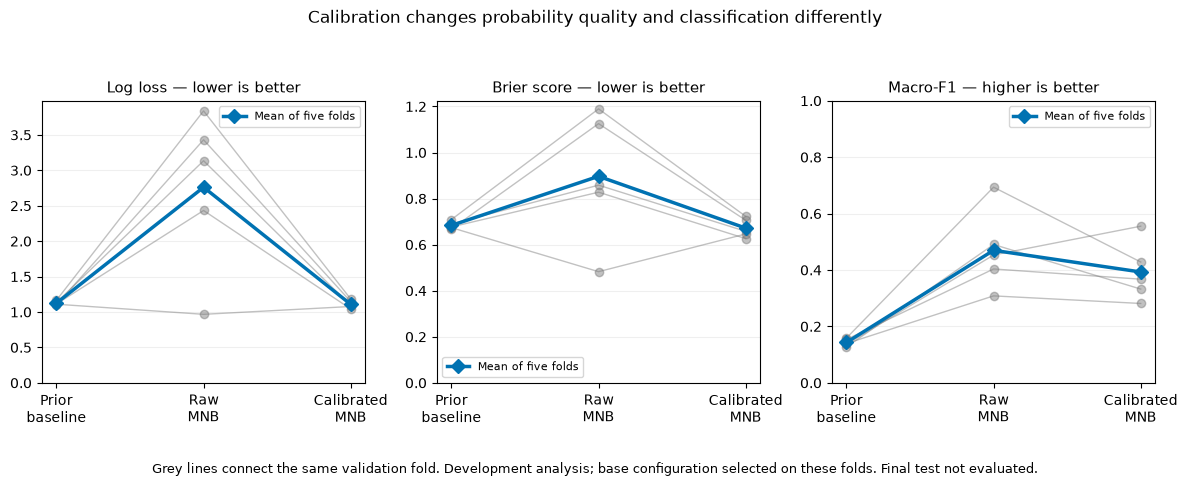

CHANGES IN CLASSIFICATION
Wrong → correct: 7
Correct → wrong: 14
Both correct: 71
Both wrong: 92

Saved: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\naive_bayes\selected_checkpoint_20261030T023553086818Z\sigmoid_calibration_20261030T030421381313Z
No new models fitted.


In [12]:
#  Paired calibration trade-off, including the prior baseline
# Existing results only. No fitting or final-test evaluation.

baseline_rows = []

for fold, rows in probability_oof.loc[
    probability_oof["model"].eq("Prior baseline")
].groupby("validation_fold"):
    baseline_rows.append({
        "model": "Prior baseline",
        "fold": fold,
        **probability_scores(rows["actual"], rows[prob_columns].to_numpy()),
        "accuracy": accuracy_score(rows["actual"], rows["predicted"]),
        "macro_f1": f1_score(
            rows["actual"], rows["predicted"],
            labels=CLASSES, average="macro", zero_division=0,
        ),
    })

tradeoff_scores = pd.concat([
    pd.DataFrame(baseline_rows),
    calibration_fold_scores,
], ignore_index=True)

order = [
    "Prior baseline",
    "Multinomial NB",
    "MNB + sigmoid calibration",
]
short_labels = ["Prior\nbaseline", "Raw\nMNB", "Calibrated\nMNB"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4.8))

for ax, metric, title in [
    (axes[0], "log_loss", "Log loss — lower is better"),
    (axes[1], "brier_sum", "Brier score — lower is better"),
    (axes[2], "macro_f1", "Macro-F1 — higher is better"),
]:
    paired = tradeoff_scores.pivot(
        index="fold", columns="model", values=metric
    ).reindex(columns=order)

    for fold, row in paired.iterrows():
        ax.plot(
            range(3), row.to_numpy(),
            color="#777777", alpha=0.45, marker="o", linewidth=1,
        )

    ax.plot(
        range(3), paired.mean().to_numpy(),
        color="#0072B2", linewidth=2.5, marker="D",
        markersize=7, label="Mean of five folds",
    )
    ax.set_xticks(range(3), short_labels)
    ax.set_title(title, fontsize=11)
    ax.grid(axis="y", alpha=0.2)
    ax.set_ylim(bottom=0)

    if metric == "macro_f1":
        ax.set_ylim(0, 1)
    ax.legend(fontsize=8)

fig.suptitle("Calibration changes probability quality and classification differently")
fig.text(
    0.5, 0.015,
    "Grey lines connect the same validation fold. Development analysis; "
    "base configuration selected on these folds. Final test not evaluated.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=[0, 0.08, 1, 0.93])
fig.savefig(
    calibration_dir / "calibration_tradeoff.png",
    dpi=180, bbox_inches="tight",
)
fig.savefig(
    calibration_dir / "calibration_tradeoff.svg",
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

# Identify changed decisions without assuming calibration always helps.
paired_predictions = raw_mnb[
    ["recording_id", "actual", "predicted"]
].merge(
    calibrated_oof[["recording_id", "actual", "predicted"]],
    on="recording_id",
    validate="one_to_one",
    suffixes=("_raw", "_calibrated"),
)
assert paired_predictions["actual_raw"].eq(
    paired_predictions["actual_calibrated"]
).all()

raw_correct = paired_predictions["actual_raw"].eq(
    paired_predictions["predicted_raw"]
)
calibrated_correct = paired_predictions["actual_raw"].eq(
    paired_predictions["predicted_calibrated"]
)

print("CHANGES IN CLASSIFICATION")
print("Wrong → correct:", int((~raw_correct & calibrated_correct).sum()))
print("Correct → wrong:", int((raw_correct & ~calibrated_correct).sum()))
print("Both correct:", int((raw_correct & calibrated_correct).sum()))
print("Both wrong:", int((~raw_correct & ~calibrated_correct).sum()))

tradeoff_scores.to_csv(
    calibration_dir / "tradeoff_with_baseline.csv", index=False
)
paired_predictions.to_csv(
    calibration_dir / "paired_classification_changes.csv", index=False
)

print("\nSaved:", calibration_dir)
print("No new models fitted.")